# P1 · Bicicletas iniciales considerando salidas y llegadas

**Pregunta de negocio:** ¿cuántos viajes se iniciarán por estación hasta terminar el primer pico matutino y con cuántas bicicletas debería iniciar cada estación para atender los viajes registrados?

Predecimos salidas y llegadas por hora. Con esos pronósticos calculamos el mayor faltante acumulado y añadimos un margen estimado con validación. Una bicicleta que regresa puede volver a utilizarse.

Este notebook presenta el análisis y los resultados del pipeline de P1. El entrenamiento y el registro de experimentos se realizan desde los módulos de `src/`.

## 1. Datos y ejecución

Periodo: **enero de 2025–septiembre de 2026**. Se utilizan las estaciones con salidas en enero de 2025. Los movimientos posteriores permiten evaluar el comportamiento de esa misma cohorte.

Desde la raíz del repositorio, el pipeline se ejecuta así:

```bash
python -m src.data.p1_dataset
python -m src.features.p1_features
python -m src.models.p1_train
```

El manifiesto conserva los hashes de los archivos y el conteo de duplicados eliminados. Los originales permanecen en `data/raw/`; los agregados y las características se guardan fuera de Git.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display
carpeta = Path.cwd()
if carpeta.name == 'notebooks':
    carpeta = carpeta.parent
sys.path.insert(0, str(carpeta))
from src import p1_config as cfg
from src.data.p1_dataset import load_prepared
hourly, manifest = load_prepared()

In [2]:
resumen = json.loads((cfg.REPORTS / 'resumen.json').read_text())
metricas = pd.read_csv(cfg.REPORTS / 'metricas.csv')
calidad = pd.DataFrame(manifest['files'])
print('Viajes conservados:', manifest['clean_trips'])
print('Duplicados eliminados:', calidad['duplicates_removed'].sum())
print('Estaciones evaluadas:', resumen['stations'])
calidad[['file', 'raw_rows', 'clean_rows', 'duplicates_removed']].tail()

Viajes conservados: 7893339
Duplicados eliminados: 758
Estaciones evaluadas: 368


,file,raw_rows,clean_rows,duplicates_removed
16,datos_abiertos_2026_05.csv,315895,315895,0
17,datos_abiertos_2026_06.csv,355303,355303,0
18,datos_abiertos_2026_07.csv,388257,388257,0
19,datos_abiertos_2026_08.csv,393524,393524,0
20,datos_abiertos_2026_09.csv,490056,489298,758


## 2. ¿Cómo contamos salidas y llegadas?

- **Salida:** estación `Origen_Id` y hora de `Inicio_del_viaje`.
- **Llegada:** estación `Destino_Id` y hora de `Fin_del_viaje`.

Un viaje que sale a las 06:50 y termina a las 07:10 aporta una salida entre 06:00 y 07:00 en su origen y una llegada entre 07:00 y 08:00 en su destino. Se conserva este criterio cuando cruza de día o mes.

Las llegadas del 1 de enero de 2025 pueden estar incompletas por viajes iniciados en diciembre de 2024. El entrenamiento comienza en febrero, fuera de esa frontera y sus rezagos.

In [3]:
hourly.head(10)

,estacion,timestamp,salidas,llegadas
0,2,2025-01-01 06:00:00,0,2
1,2,2025-01-01 08:00:00,1,0
2,2,2025-01-01 09:00:00,1,0
3,2,2025-01-01 10:00:00,1,1
4,2,2025-01-01 12:00:00,0,1
5,2,2025-01-01 14:00:00,0,1
6,2,2025-01-01 16:00:00,1,0
7,2,2025-01-01 17:00:00,0,1
8,2,2025-01-01 18:00:00,3,2
9,2,2025-01-01 19:00:00,3,3


## 3. Primera franja de mayor actividad en la mañana

Buscamos las tres horas consecutivas con más salidas entre las 06:00 y las 12:00, usando **solo 2025**. Distinguimos lunes–viernes y fin de semana; no tratamos feriados por separado. Las franjas son comunes al sistema, no específicas de cada estación.

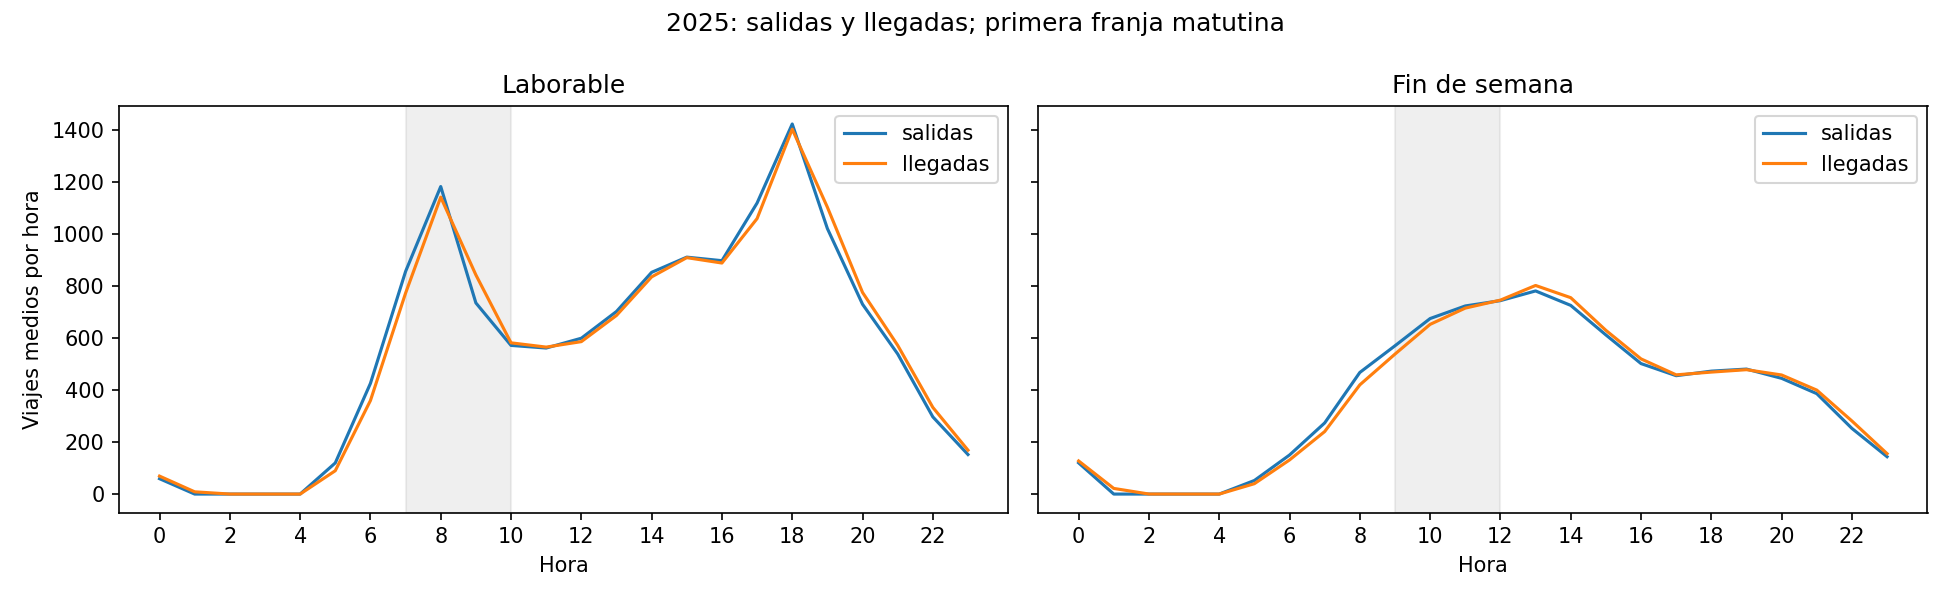

,inicio_pico,hora_fin
Laborable,7,10
Fin de semana,9,12


In [4]:
display(Image(filename=str(cfg.FIGURES / '01_perfil_flujos.png')))
franjas = pd.read_csv(cfg.REPORTS / 'franjas.csv', index_col=0)
franjas

## 4. Información disponible antes de empezar el día

La rejilla contiene una fila por estación, fecha y hora de 00:00 a 11:00. Una hora sin movimientos registrados se completa con cero. Esto no confirma que la estación estuviera abierta o tuviera bicicletas.

Las entradas del modelo son las salidas y llegadas de la misma hora de **ayer** y de **hace una semana**, la hora, el día de semana y el mes. No se utilizan movimientos del día pronosticado como entrada.

| Periodo | Uso |
|---|---|
| Febrero–diciembre de 2025 | Entrenamiento |
| Enero–junio de 2026 | Selección de métodos y calibración del margen |
| Julio–septiembre de 2026 | Evaluación final |

La evaluación simula una nueva previsión a medianoche cada día, con la historia real disponible hasta el día anterior.

In [5]:
print('Variables:', ', '.join(cfg.VARIABLES))
pd.Series({
    'Filas de entrenamiento': resumen['training_rows'],
    'Filas de validación': resumen['validation_rows'],
    'Filas de prueba': resumen['test_rows']
})

Variables: hora, dia_semana, mes, salidas_ayer, salidas_semana, llegadas_ayer, llegadas_semana


Filas de entrenamiento    1474944
Filas de validación        799296
Filas de prueba            406272
dtype: int64

## 5. Comparación de tres alternativas

1. **Semanal:** repetir los viajes de la misma estación y hora de hace siete días.
2. **Histórico:** promedio de entrenamiento por estación, día de semana y hora, incluyendo horas con cero.
3. **Árboles:** un árbol de regresión para salidas y otro para llegadas, con profundidad máxima 10 y mínimo 100 observaciones por hoja.

Las tres alternativas se evalúan sobre **las mismas filas**. Para cada flujo elegimos el método con menor MAE en validación. La fila `seleccionado` reúne las decisiones finales.

MAE y RMSE de flujos se expresan en viajes por estación y hora.

In [6]:
columnas_flujos = ['metodo', 'salidas_mae', 'salidas_rmse', 'llegadas_mae', 'llegadas_rmse']
metricas.loc[metricas['particion'].eq('validation'), columnas_flujos].round(3)

,metodo,salidas_mae,salidas_rmse,llegadas_mae,llegadas_rmse
0,semanal,0.651,1.461,0.602,1.382
2,historico,0.596,1.239,0.561,1.177
4,arbol,0.599,1.234,0.566,1.167
6,seleccionado,0.596,1.239,0.561,1.177


In [7]:
print('Métodos seleccionados:', resumen['selected_methods'])
metricas.loc[metricas['particion'].eq('test'), columnas_flujos].round(3)

Métodos seleccionados: {'salidas': 'historico', 'llegadas': 'historico'}


,metodo,salidas_mae,salidas_rmse,llegadas_mae,llegadas_rmse
1,semanal,0.679,1.483,0.638,1.414
3,historico,0.620,1.262,0.601,1.259
5,arbol,0.624,1.275,0.596,1.220
7,seleccionado,0.620,1.262,0.601,1.259


## 6. Convertir los flujos en bicicletas iniciales

Imaginamos que iniciamos con cero bicicletas y seguimos el balance: restamos salidas y sumamos llegadas. El punto de mayor faltante determina la necesidad inicial.

Usamos un orden conservador dentro de cada hora: **primero salen las bicicletas y después llegan las devoluciones**. Por eso no restamos únicamente los totales al final de la mañana.

Con salidas `[10, 6, 3]` y llegadas `[2, 4, 7]`, el saldo mínimo es −14; la necesidad inicial es 14 bicicletas. El neto al final es −6, pero empezar con 6 no cubre los faltantes anteriores.

In [8]:
from src.models.p1_balance import calculate_balance, summarize_balance
peaks = franjas.copy()
ejemplo = pd.DataFrame({
    'estacion': [1, 1, 1], 'fecha': pd.to_datetime(['2026-09-30'] * 3),
    'hora': [7, 8, 9], 'salidas_previstas': [10, 6, 3], 'llegadas_previstas': [2, 4, 7]
})
balance = calculate_balance(ejemplo, peaks)
balance[['hora', 'salidas_previstas', 'llegadas_previstas', 'saldo_minimo_hora', 'saldo_fin']]

,hora,salidas_previstas,llegadas_previstas,saldo_minimo_hora,saldo_fin
0,7,10,2,-10,-8
1,8,6,4,-14,-10
2,9,3,7,-13,-6


In [9]:
summarize_balance(balance)[['necesidad']]

,,necesidad
estacion,fecha,
1,2026-09-30,14


## 7. Añadir un margen

El margen es el percentil 90 de los errores de subestimación de la necesidad inicial en validación. Se suma al requerimiento previsto y se redondea hacia arriba.

Es un margen global empírico, no una garantía de servicio por estación. Selección y calibración comparten validación; la prueba final se mantiene independiente.

In [10]:
print('Margen seleccionado:', round(resumen['margin'], 2), 'bicicletas')
columnas_stock = ['metodo', 'inventario_mae', 'inventario_rmse',
                  'cobertura_conteos_sin_limite_capacidad']
metricas.loc[metricas['particion'].eq('test'), columnas_stock].round(3)

Margen seleccionado: 3.19 bicicletas


,metodo,inventario_mae,inventario_rmse,cobertura_conteos_sin_limite_capacidad
1,semanal,2.189,3.331,0.899
3,historico,2.048,3.085,0.913
5,arbol,1.988,3.072,0.928
7,seleccionado,2.048,3.085,0.913


El MAE de inventario mide el error del **requerimiento conservador sin margen** en bicicletas por estación y día. La cobertura indica cuántas referencias alcanzan el requerimiento horario observado antes de restringir por capacidad. No mide usuarios atendidos ni demanda rechazada.

Las métricas de flujo incluyen horas de poca actividad; su promedio no representa necesariamente el error de las horas pico.

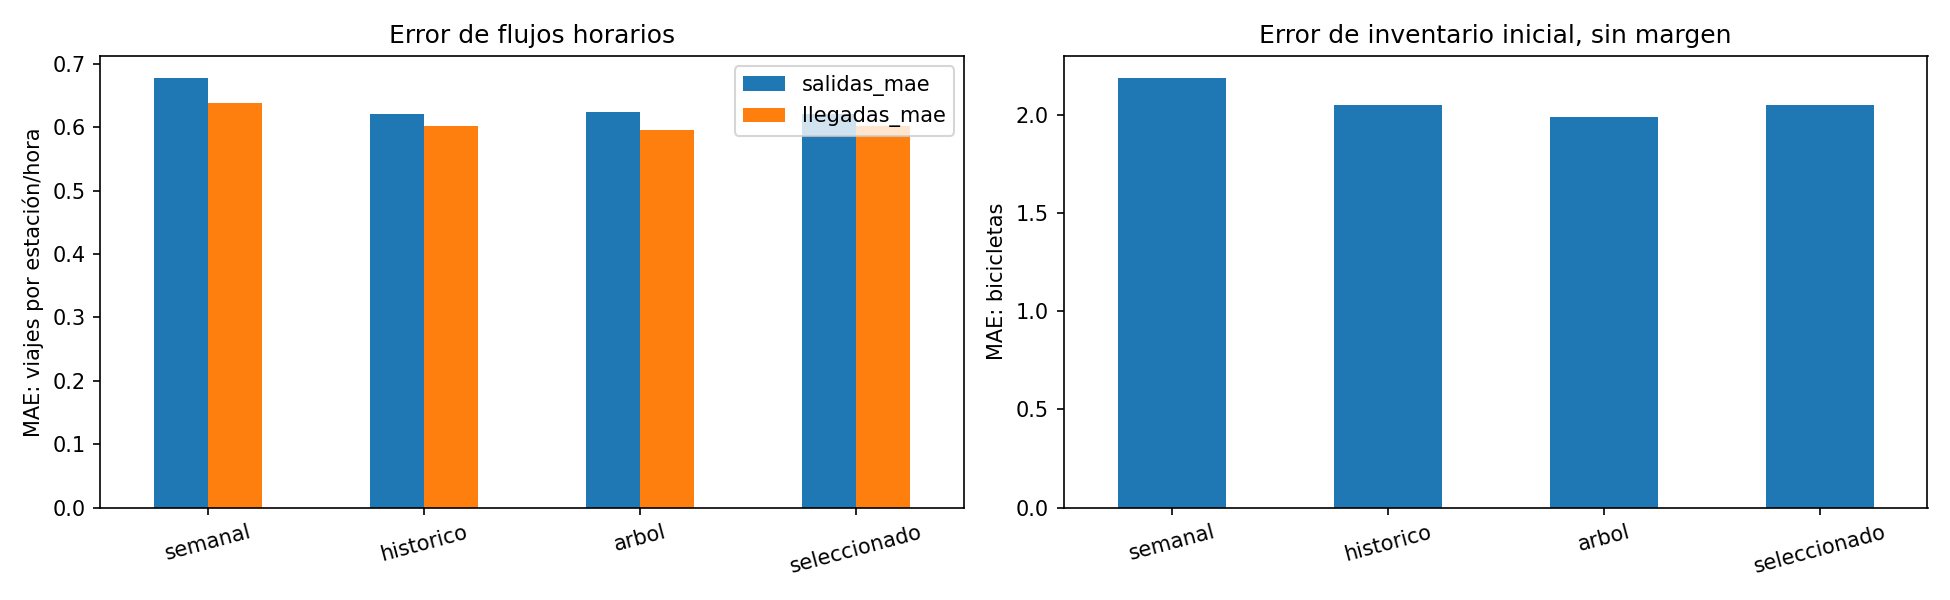

In [11]:
display(Image(filename=str(cfg.FIGURES / '05_comparacion_modelos.png')))

## 8. Efecto de reutilizar bicicletas

Comparamos la suma de las salidas previstas con el requerimiento calculado al incluir las llegadas de esas mismas previsiones. Ambos valores excluyen el margen para aislar el efecto de la reutilización.

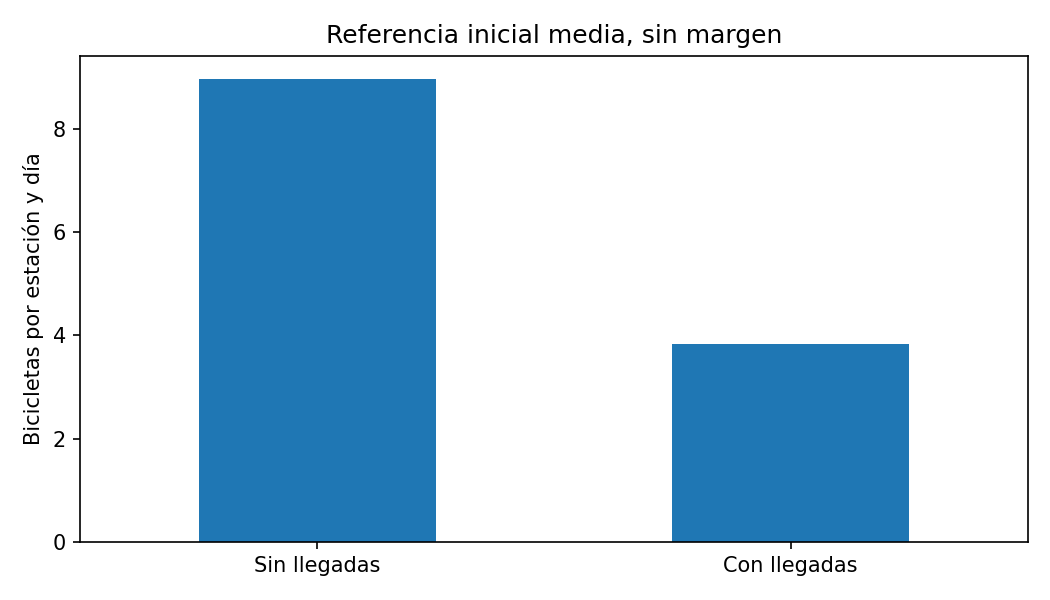

In [12]:
display(Image(filename=str(cfg.FIGURES / '02_efecto_llegadas.png')))

## 9. Recomendación por estación y capacidad

El ejemplo retrospectivo corresponde al **30 de septiembre de 2026** y utiliza el catálogo de ese mes como aproximación de capacidad. La capacidad no forma parte de las variables de entrenamiento.

Se revisa que quepan las bicicletas iniciales y que exista espacio para las devoluciones previstas. Las referencias que rebasan la capacidad no generan una sugerencia numérica. Las estaciones sin actividad durante los 28 días anteriores quedan señaladas en el resultado.

In [13]:
recomendacion = pd.read_csv(cfg.REPORTS / 'sugerencia_ejemplo.csv')
recomendacion['estado'].value_counts().rename('Estaciones')

estado
Sugerencia revisable                        329
Falta espacio previsto para devoluciones     19
Inventario inicial supera capacidad          18
Confirmar operación                           2
Name: Estaciones, dtype: int64

In [14]:
columnas = ['estacion', 'nombre', 'inicio_pico', 'hora_fin', 'bicicletas_referencia',
            'capacidad', 'bicicletas_inicio_sugeridas', 'estado']
recomendacion[columnas].head(12)

,estacion,nombre,inicio_pico,hora_fin,bicicletas_referencia,capacidad,bicicletas_inicio_sugeridas,estado
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,7,10,13,15,13.0,Sugerencia revisable
1,3,(GDL-002) C. Colonias / Av. Niños héroes,7,10,9,15,9.0,Sugerencia revisable
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,7,10,5,19,5.0,Sugerencia revisable
3,5,(GDL-004) C. Ghilardi /C. Miraflores,7,10,15,19,15.0,Sugerencia revisable
4,6,(GDL-005) C. San Diego /Calzada Independencia,7,10,6,11,6.0,Sugerencia revisable
5,8,(GDL-006) C. Venustiano Carranza /C. Reforma,7,10,8,11,8.0,Sugerencia revisable
6,9,(GDL-007) C. Epigmenio Glez./Av. Cristobal C.,7,10,13,15,13.0,Sugerencia revisable
7,10,(GDL-008) C. Ignacio Zaragoza / C. J. Angulo,7,10,13,15,13.0,Sugerencia revisable
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,7,10,37,23,NaN,Inventario inicial supera capacidad
9,12,(GDL-010) C. Cruz verde / C. Joaquin Angulo,7,10,14,15,14.0,Sugerencia revisable


## 10. Balance previsto y observado de una estación

La gráfica selecciona una estación con alta actividad histórica entre las sugerencias compatibles con la capacidad prevista. Compara el saldo construido con pronósticos con el saldo que se obtiene después usando los flujos observados.

Los puntos a media hora representan el orden supuesto, no los momentos reales de cada viaje. Un saldo negativo significa un faltante bajo ese supuesto; no representa un inventario físico negativo. La curva observada puede mostrar faltantes aun cuando la curva prevista permanezca positiva.

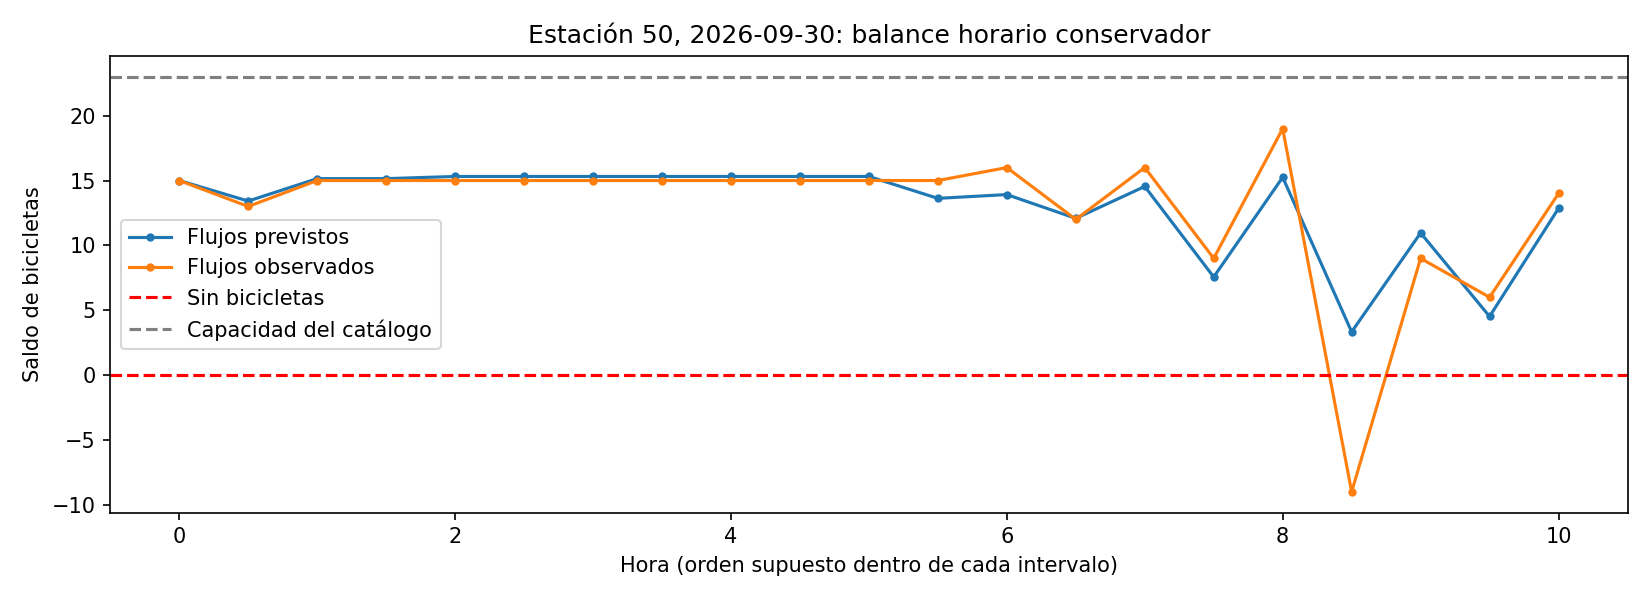

In [15]:
display(Image(filename=str(cfg.FIGURES / '03_balance_estacion.png')))

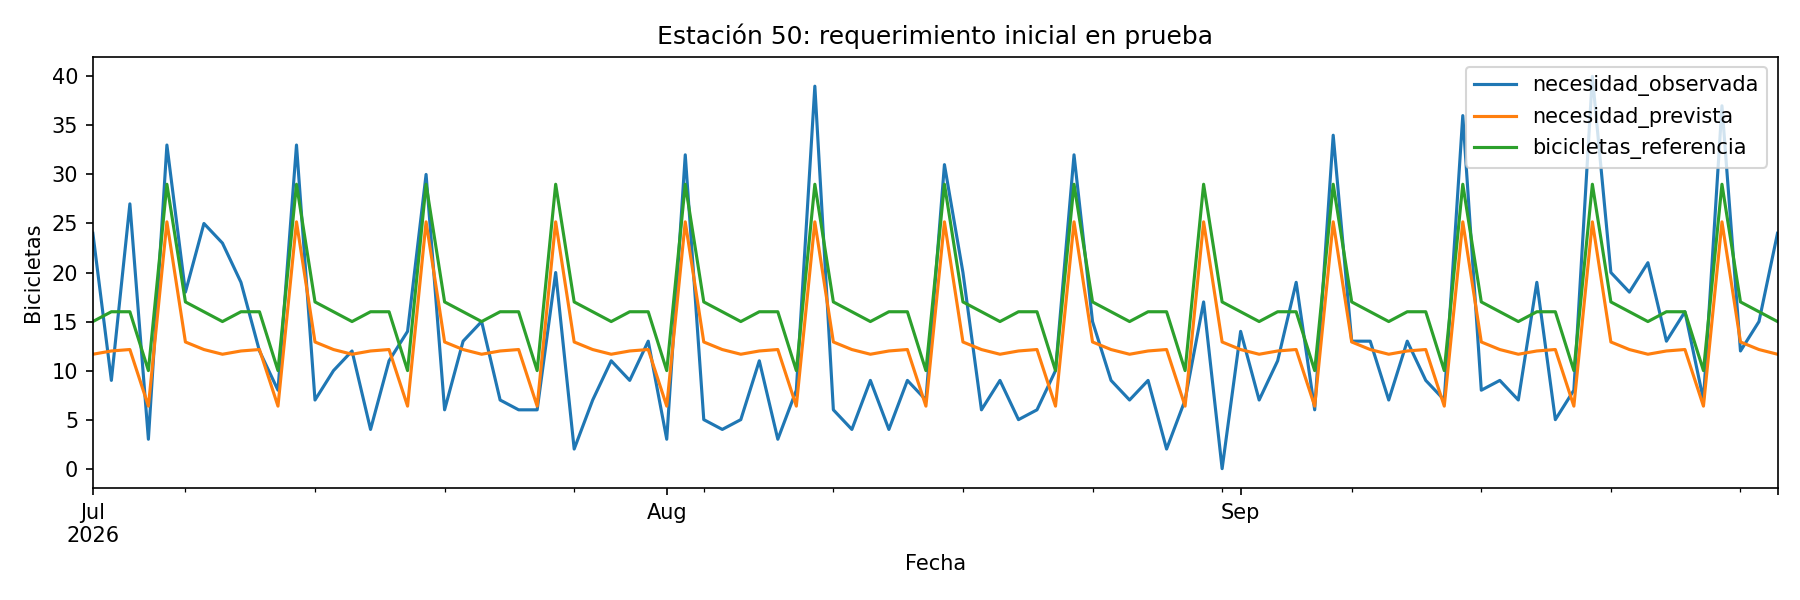

In [16]:
display(Image(filename=str(cfg.FIGURES / '04_necesidad_prueba.png')))

## 11. Trazabilidad de los experimentos

Las corridas de P1 se registran bajo `mibici-equipo30` en MLflow, con versión de datos, fechas, parámetros, métricas, commit y copia del código ejecutado. La corrida seleccionada incluye el modelo serializado y las figuras. Los identificadores que aparecen a continuación corresponden a esta ejecución local.

In [17]:
corridas = pd.read_json(cfg.REPORTS / 'mlflow_runs.json')
corridas[['metodo', 'run_id']]

,metodo,run_id
0,semanal,7f215a21218d4dc69f301dd371a49937
1,historico,df1d61f57de04cf480d79fd4da98f5ee
2,arbol,3f2d682eb35e4e198889a4df9a24a84d
3,seleccionado,c50ae35534fa4800ba4f7001e78675b0


## 12. Inferencia diaria

La inferencia utiliza el modelo guardado y solo los movimientos anteriores al día solicitado:

```bash
python -m src.models.p1_predict --date 2026-10-01
```

Con historia completa hasta septiembre de 2026 puede emitir una referencia para el 1 de octubre. Esa salida es una demostración histórica del método, no una recomendación vigente para una fecha posterior sin datos nuevos.

## Alcance y límites

- Se estiman necesidades a partir de viajes realizados. No se observan solicitudes rechazadas ni redistribuciones hechas por el operador.
- El día comienza a las 00:00 y no se supone reabastecimiento hasta el final de la primera franja.
- El orden horario conservador puede pedir más bicicletas que un cálculo con tiempos exactos.
- Los ceros pueden incluir cierres desconocidos. Las estaciones nuevas quedan fuera de la cohorte inicial.
- El margen global no ofrece el mismo nivel de cobertura a todas las estaciones.
- El catálogo de septiembre aproxima la capacidad del ejemplo; no se interpreta como capacidad histórica de todo el periodo.
- El resultado es una referencia de inventario inicial, no una medición del inventario actual.